# Lab: Histogram-based Similarity Retrieval

## Import required packages

## Goal of this lab

This Lab aims at implementing a histogram-based similarity retrieval system for images. For a given query image the system should return the three most similar images. The dataset, which you can download from the ecampus course website is a subselection of Kaggle's [Fruits 360](https://www.kaggle.com/moltean/fruits) dataset. The basic idea for the retrieval system is to determine a histogram per each channel (Red, Green, Blue) of an image. After concatinating these into a feature vector we store this feature vector into a feature vector database. We choose one test image and from this determine also histograms and consequently a feature vector. In order to calculate the most similar images, we substract (we need the absolute difference) the test feature vector from the stored training feature vectors and determine the 3 smallest differences. In the end, we will plot the three most similar images next to the query image.


## Required reading
* Numpy docs on the function _histogram_: https://docs.scipy.org/doc/numpy/reference/generated/numpy.histogram.html


## Required packages
* numpy
* os
* matplotlib
* imageio

You can execute individual code blocks by pressing SHIFT+Enter consecutively.

You can trigger auto completion with TABULATOR

In [1]:
import numpy as np
import os 
import imageio.v2 as imageio
import matplotlib.pyplot as plt

## Provided functions
* _loadImages_: loads all images from a folder within the specified path
* _plotSubplots_: plots all images which are provided to the function as subplots in a horizontal way, the first parameter is the original image as numpy array, and the second an numpy array containing other images as numpy arrays

In [2]:
def loadImages(path):
    images = []
    for filename in os.listdir(path):
        try:
            img = imageio.imread(os.path.join(path, filename))
            if img is not None:
                images.append(img)
        except:
            print('Cannot import ' + filename)
    images = np.asarray(images)
    return images

def plotSubplots(originalImg, images):
    if images.ndim == 3:
        images = np.vstack((originalImg[None,:],images[None,:]))
    else:
        images = np.vstack((originalImg[None,:],images))
    
    fig, axArray = plt.subplots(1, images.shape[0], sharey=True)
    
    for ax, img in zip(axArray.flatten(),images):
        ax.imshow(img)

## Exercise 1 
### Read in train images

1. Specify the path to the folder where the training data is stored as a string
2. Call the provided function _loadImages_, pass the specified path as parameter
3. Store the return value in a variable called _images_
4. Print the shape of the array containing the images (with _.shape_) and explain what each of the numbers mean

Note: on Windows, do not use backslash ("\"), use forward slash "/" instead!

In [3]:
path = "../../data/test_images/fruits/train"
images = loadImages(path)
print(images.shape)

Cannot import trainLabels.txt
(60, 100, 100, 3)


meaning of numbers: image count, height in px, width in px, color channels (RGB)

### Read in test images

1. Specify the path to the folder where the test data is stored as a string
2. Call the provided function _loadImages_, pass the specified path as parameter
3. Store the return value in a variable _testImages_

Note: on Windows, do not use backslash "\\", use forward slash "/" instead!

In [4]:
testPath = "../../data/test_images/fruits/test"
testImages = loadImages(testPath)

### Calculate a histogram for each channel of an RGB image

1. Define a function, called _calculateHist_; it should take two parameters _img_ (RGB image) and _nBins_ (number of bins in the histogram)
2. You need the _np.histogram_ function to determine the histograms, read the numpy docs on the function _histogram_
3. You can access a specific channel of an image with the right-most index, e.g. [:,:,0] is the red channel
4. Before you provide one channel of the image to the _np.histogram_ function you need to flatten the channel from a 2D array into a 1D array (with _np.ndarray.flatten()_)
5. Additionally, you need to generate bin edges for the histogram. You can do this by using _bin_edges_ = np.linspace(0, 255, _num_=_nBins_+1)
5. Provide the flattened channel and _bin_edges_ to the _np.histogram_ function
6. Store the two return values: the values of the histogram and the edges of the bins
7. Repeat the previous steps for each channel (Red, Green, and Blue)
8. Your function _calculateHist_ should have three return values: the values of the histograms from each channel

In [5]:
def calculateHist(img, nBins):
    bin_edges = np.linspace(0, 255, num=nBins+1)
    
    histR, _ = np.histogram(img[:,:,0].flatten(), bin_edges)
    histG, _ = np.histogram(img[:,:,1].flatten(), bin_edges)
    histB, _ = np.histogram(img[:,:,2].flatten(), bin_edges)
    
    return histR, histG, histB

## Exercise 2
### Calculate the feature vectors for single images and plot them
1. First plot three images at the indices 0,2 and 50. Hint: e.g., use img1 = images[0], etc.
2. Next, use the function calculateHist for all three images and save the results in the variables h1,h2 and h3. Use _nBins_ = 60
3. For the creation of histogram plots, we need to compute the array _bin_edges_ again via np.linspace (again with 0,255 and _nBins_+1)
4. Now for every image, plot a histogram for the the Red channel. Hint: for the first image use plt.hist(_bin_edges_[:-1], _bin_edges_, weights=_h1_[0]) and plt.show().

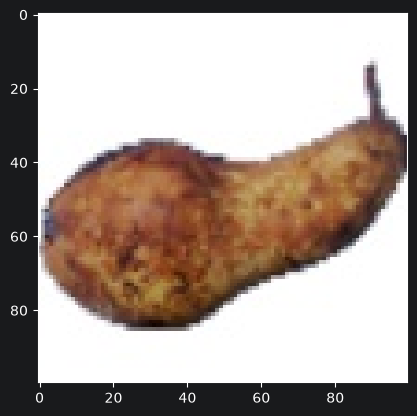

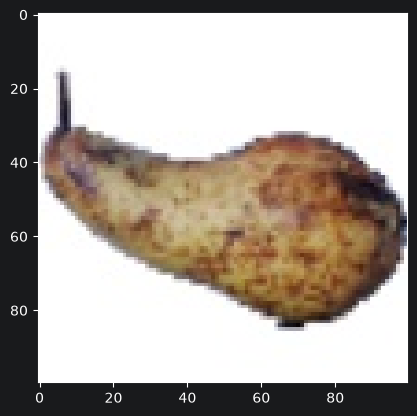

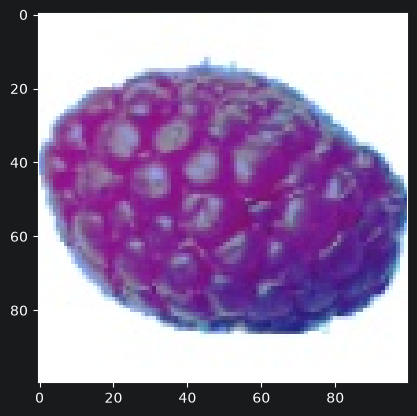

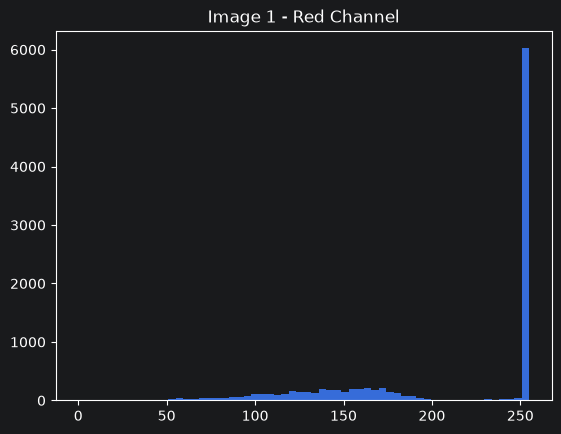

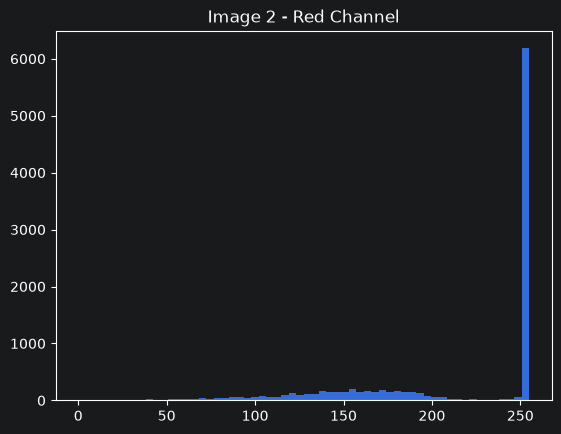

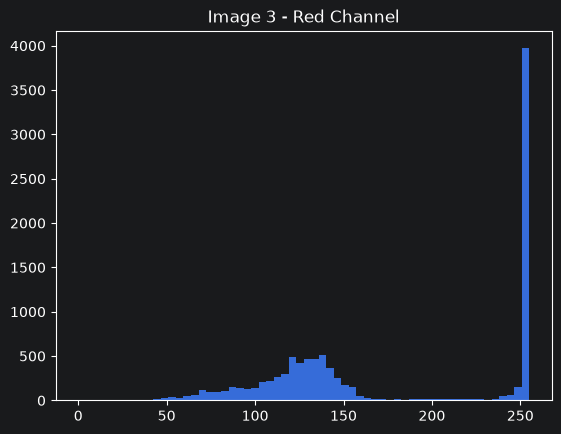

In [6]:
img1 = images[0]
img2 = images[2]
img3 = images[50]

plt.imshow(img1)
plt.show()
plt.imshow(img2)
plt.show()
plt.imshow(img3)
plt.show()

nBins = 60
h1 = calculateHist(img1, nBins)
h2 = calculateHist(img2, nBins)
h3 = calculateHist(img3, nBins)

bin_edges = np.linspace(0, 255, num=nBins+1)

plt.hist(bin_edges[:-1], bin_edges, weights=h1[0])
plt.title("Image 1 - Red Channel")
plt.show()

plt.hist(bin_edges[:-1], bin_edges, weights=h2[0])
plt.title("Image 2 - Red Channel")
plt.show()

plt.hist(bin_edges[:-1], bin_edges, weights=h3[0])
plt.title("Image 3 - Red Channel")
plt.show()

### Calculate the feature vectors for each train image
1. Define the variable _nBins_ and assign the value 60 to it 
2. Define a numpy array called _featureVecDict_ which should be initialized with 0 and should have the following shape: number of rows = number of images, number of columns = 3 * _nBins_ (use _np.zeros_)
3. Define a for loop which iterates over all train images
4. In the for loop call the function _calculateHist_ and save the three return values
5. Concatenate the three histograms and store the result into a variable called _featureVec_ (use _np.concatenate_)
6. You can use the same control variable as for the loop or define one on your own, but you should replace one row in the _featureVecDict_ with the variable _featureVec_ on each iteration:     
```python
featureVecDict[i,:] = featureVec
```

Note: np.concatenate needs a tuple as parameter:
```python
A = np.concatenate((B,C,D))
```

In [7]:
nBins = 60
featureVecDict = np.zeros((len(images), 3 * nBins))

for i in range(len(images)):
    r, g, b = calculateHist(images[i], nBins)
    featureVec = np.concatenate((r, g, b))
    featureVecDict[i,:] = featureVec

## Exercise 3 
### Calculate the feature vectors for each test image and build your first retrieval system
1. Define a for loop which iterates over all test images
2. In the for loop call the function _calculateHist_ and save the three return values
3. Concatenate the three histograms and store the result into a variable called _featureVec_ (use _np.concatenate_)
4. Subtract the current _featureVec_ from the _featureVecDict_ matrix and store it into a variable called _difference_
5. Use the function _np.abs_ to determine the absolut values of the differences between the dictionary and the current feature vector
6. Sum the values of the variable _difference_ row-wise (use sum, set the parameter _axis_ correctly)
7. Determine the index of the value which has the smallest absolute difference to the current feature vector (use _argmin_)
8. Call the provided function _plotSubplots_ an pass the current test image and the most closest image as parameters





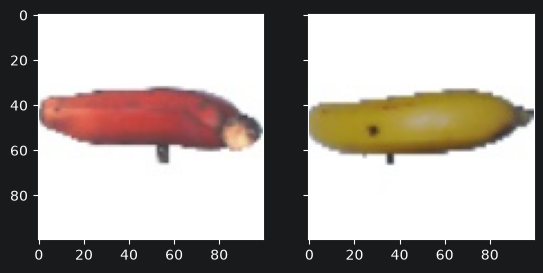

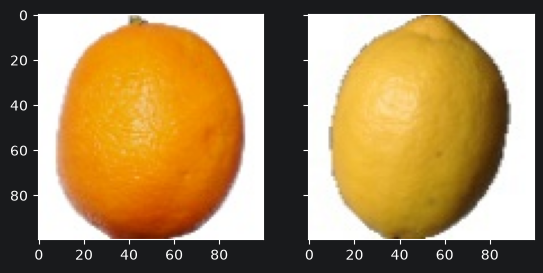

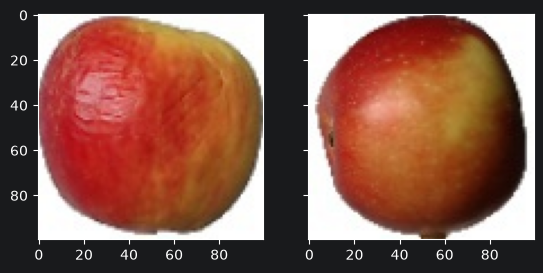

In [8]:
for i in range(len(testImages)):
    r, g, b = calculateHist(testImages[i], nBins)
    featureVec = np.concatenate((r, g, b))
    
    difference = featureVecDict - featureVec
    difference = np.abs(difference)
    difference = difference.sum(axis=1)
    
    closest = difference.argmin()
    plotSubplots(testImages[i], images[closest])
    plt.show()

## Exercise 4
### Extend your retrieval system so that the 3 most similar images are returned
1. Define a variable called n and assign the value 3 to it
2. Copy the existing code 
3. Change the line in the code where you determine the smallest difference so that you determine the n smallest differences:
    1. Instead of argmin use argsort which returns the indices that would sort the array
    2. Save the return value of argsort into a variable into a variable called _sortedArr_ and plot it 
    3. Save the first *n* values of _sortedArr_ into a new variable called _closestImages_
    4. Call the provided function plotSubplots an pass the current test image and the *3* most closest images (_images[closestImages]_) as parameters









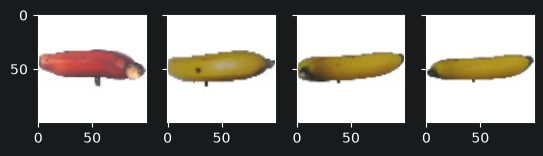

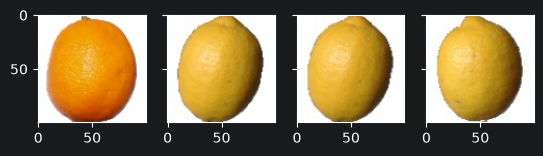

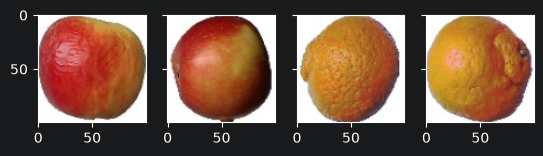

In [9]:
n = 3

for i in range(len(testImages)):
    r, g, b = calculateHist(testImages[i], nBins)
    featureVec = np.concatenate((r, g, b))
    
    difference = featureVecDict - featureVec
    difference = np.abs(difference)
    difference = difference.sum(axis=1)
    
    sortedArr = difference.argsort()
    closestImages = sortedArr[:n]
    plotSubplots(testImages[i], images[closestImages])
    plt.show()